> ⚡ **GPU version** of the GStatSim book chapter *Sequential Gaussian simulation*  
> Original: [4_Sequential_Gaussian_Simulation](https://gatorglaciology.github.io/gstatsimbook/4_Sequential_Gaussian_Simulation.html), Gator Glaciology Lab. Only the slow steps changed: GStatSim's kriging and SGS calls run through `gstatsim_accel` (`backend=BACKEND`), timed with `%%time` next to the CPU time recorded in the published book. Everything else is the book's own text and code.

In [1]:
# GPU version: pick the backend, and fetch the book's data if it's missing.
from pathlib import Path
from urllib.request import urlretrieve

from gstatsim_accel import gpu_status, kriging, simulation

BACKEND = "gpu" if gpu_status().available else "cpu"
print("Backend:", BACKEND, "|", gpu_status().device_name or gpu_status().reason)

DATA_URL = "https://raw.githubusercontent.com/GatorGlaciology/GStatSim/main/demos/data/"
for name in ("greenland_test_data.csv", "greenland_surface_data.csv"):
    if not (Path("data") / name).exists():
        Path("data").mkdir(exist_ok=True)
        urlretrieve(DATA_URL + name, Path("data") / name)

# The book's plotting helpers, pinned to the reviewed commit.
if not Path("plot_utils.py").exists():
    urlretrieve("https://raw.githubusercontent.com/GatorGlaciology/gstatsimbook/"
                "9365b2d4ef645d6f6bc1362dbe1221b52b714e4b/plot_utils.py", "plot_utils.py")

C:\Users\alexi\miniforge3\envs\gstatsim-gpu\Lib\site-packages\cupy\_environment.py:286: UserWarning: CUDA path could not be detected. Set CUDA_PATH environment variable if CuPy fails to load.
  warnings.warn(


Backend: gpu | NVIDIA GeForce RTX 5060 Laptop GPU


# Sequential Gaussian simulation

We saw in the kriging example that kriging does not reproduce the variogram statistics of the data, making it an unrealistically smooth representation of geologically phenomena. To reproduce the variogram statistics, we perform sequential Gaussian simulation, a common method for stochastic simulation.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import QuantileTransformer 
import gstatsim as gs
import skgstat as skg
from skgstat import models
import random

# plotting utility functions
from plot_utils import splot2D, mplot1, make_colorbar

## Load and plot data

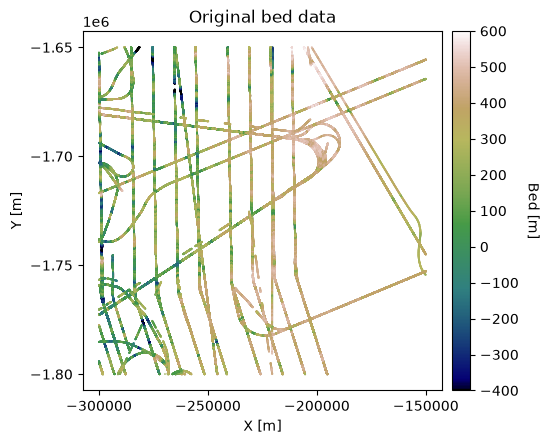

In [3]:
df_bed = pd.read_csv('data/greenland_test_data.csv')

# remove erroneously high values due to bad bed picks
df_bed = df_bed[df_bed["Bed"] <= 700]  

# plot original data
splot2D(df=df_bed, title='Original bed data')

## Grid and transform data, compute variogram parameters

In [4]:
# grid data to 100 m resolution and remove coordinates with NaNs
res = 1000
df_grid, grid_matrix, rows, cols = gs.Gridding.grid_data(df_bed, 'X', 'Y', 'Bed', res)
df_grid = df_grid[df_grid["Z"].isnull() == False]
df_grid = df_grid.rename(columns = {"Z": "Bed"})

# normal score transformation
data = df_grid['Bed'].values.reshape(-1,1)
nst_trans = QuantileTransformer(n_quantiles=500, output_distribution="normal").fit(data)
df_grid['Nbed'] = nst_trans.transform(data) 

# compute experimental (isotropic) variogram
coords = df_grid[['X','Y']].values
values = df_grid['Nbed']

maxlag = 50000             # maximum range distance
n_lags = 70                # num of bins

V1 = skg.Variogram(coords, values, bin_func='even', n_lags=n_lags, 
                   maxlag=maxlag, normalize=False)

# use exponential variogram model
V1.model = 'exponential'

## Initialize grid

Make list of grid cells that need to be simulated.

In [5]:
# define coordinate grid
xmin = np.min(df_grid['X']); xmax = np.max(df_grid['X'])     # min and max x values
ymin = np.min(df_grid['Y']); ymax = np.max(df_grid['Y'])     # min and max y values

Pred_grid_xy = gs.Gridding.prediction_grid(xmin, xmax, ymin, ymax, res)

## Sequential Gaussian simulation

Sequential Gaussian simulation (SGS) uses kriging to sequentially estimate the kriging mean and variance at each grid cell. This mean and variance define a Gaussian probability distribution from which a random value sampled in order to simulate a grid cell.

:::{figure-md} markdown-fig
<img src="./Images/SGS_cartoon-01.jpg" class="bg-primary mb-1" width="700px">

Sequential Gaussian simulation
:::

We have two versions of sequential Gaussian simulation, skrige_sgs and okrige_sgs, which use simple and ordinary kriging, respectively. In this example we use okrige_sgs.

In [6]:
%%time
# Published book (GStatSim on CPU): 2 min 27 s
# set variogram parameters
azimuth = 0
nugget = V1.parameters[2]

# the major and minor ranges are the same in this example because it is isotropic
major_range = V1.parameters[0]
minor_range = V1.parameters[0]
sill = V1.parameters[1]

# save variogram parameters as a list
vario = [azimuth, nugget, major_range, minor_range, sill, 'Exponential']  # model type: required since GStatSim 1.1

k = 48         # number of neighboring data points used to estimate a given point 
rad = 50000    # 50 km search radius

sim = simulation.sgs(df_grid, Pred_grid_xy, vario, num_points=k, radius=rad, method="ordinary", xx='X', yy='Y', zz='Nbed', backend=BACKEND) 

CPU times: total: 11.1 s
Wall time: 11.7 s


In [7]:
# reverse normal score transformation
sim1 = sim.reshape(-1,1)
sim_trans = nst_trans.inverse_transform(sim1)

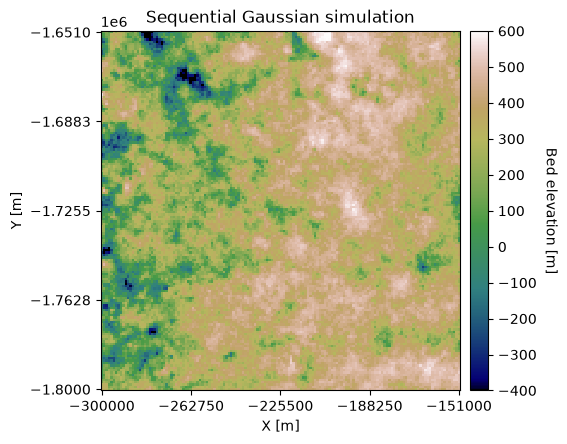

In [8]:
mplot1(Pred_grid_xy, sim_trans, rows, cols, title='Sequential Gaussian simulation', clabel='Bed elevation [m]')

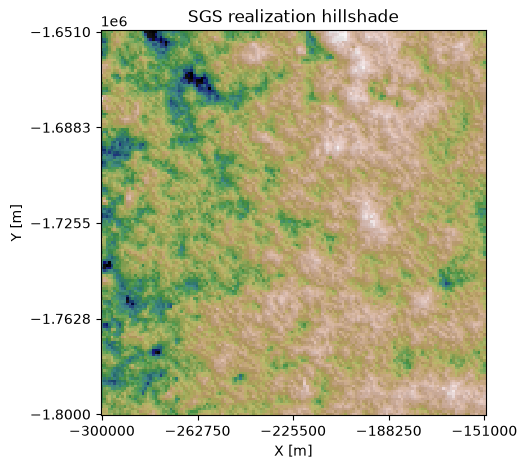

In [9]:
mplot1(Pred_grid_xy, sim_trans, rows, cols, title='SGS realization hillshade', hillshade=True)

SGS can be used to simulate multiple realizations for quantifying uncertainty. Let's generate a couple more realizations.

In [10]:
%%time
# Published book (GStatSim on CPU): 2 min 42 s, 2 min 49 s
# simulate multiple random realizations
# GPU version: both realizations in one call, simulated side by side
sim2, sim3 = simulation.realizations(df_grid, Pred_grid_xy, vario, num_points=k, radius=rad, method="ordinary", xx='X', yy='Y', zz='Nbed', seeds=[2, 3], backend=BACKEND)

# simulation 2
sim2 = sim2.reshape(-1,1)
sim2_trans = nst_trans.inverse_transform(sim2)

# simulation 3
sim3 = sim3.reshape(-1,1)
sim3_trans = nst_trans.inverse_transform(sim3)

CPU times: total: 7.64 s
Wall time: 8.27 s


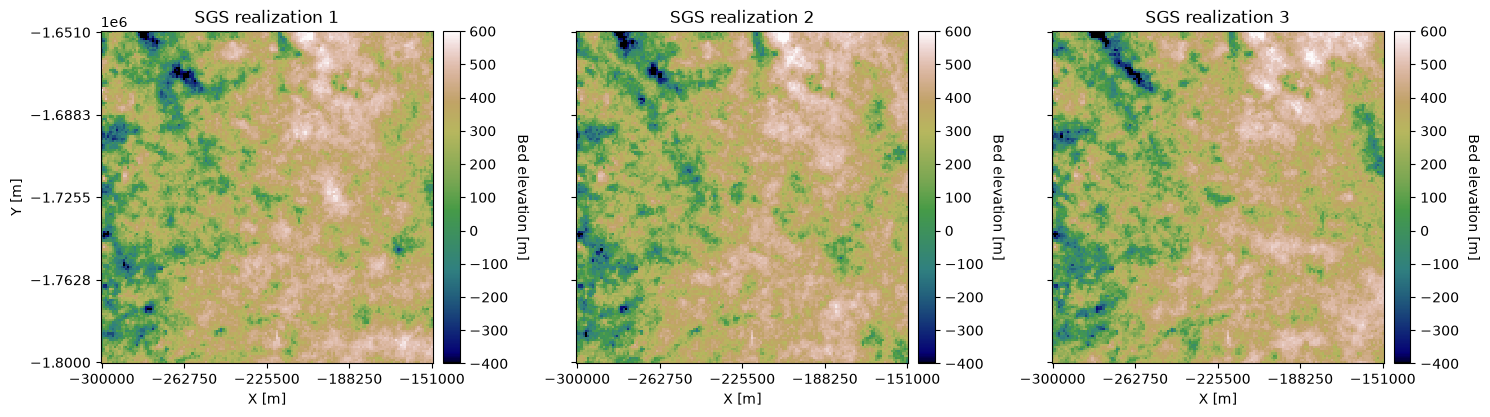

In [11]:
x_mat = Pred_grid_xy[:,0].reshape((rows, cols))
y_mat = Pred_grid_xy[:,1].reshape((rows, cols))

plots = [sim_trans, sim2_trans, sim3_trans]

fig, axs = plt.subplots(1, 3, figsize=(15,5), sharey=True)

for i, (ax, plot) in enumerate(zip(axs, plots)):
    sgs_mat = plot.reshape((rows, cols))
    im = ax.pcolormesh(x_mat, y_mat, sgs_mat, vmin=-400, vmax=600, cmap='gist_earth')
    ax.set_title(f'SGS realization {i+1}')
    ax.set_xlabel('X [m]')
    if i == 0:
        ax.set_ylabel('Y [m]')
    ax.set_xticks(np.linspace(xmin, xmax, 5))
    ax.set_yticks(np.linspace(ymin, ymax, 5))

    cbar = make_colorbar(fig, im, -400, 600, 'Bed elevation [m]', ax=ax)
    ax.axis('scaled')
    
plt.tight_layout()
plt.show()

You can see that they all look a bit different from each other.

## SGS Roughness

The topography generated using SGS is much rougher than the kriging examples. Let's check the variograms to see if the roughness statistics of the data are reproduced.

In [12]:
# compute SGS variogram

# downsample random indices to speed this up
rand_indices = random.sample(range(np.shape(Pred_grid_xy)[0]),5000)

# get coordinates and normalized simulation from random indices
coords_s = Pred_grid_xy[rand_indices]
values_s = sim[rand_indices]

VS = skg.Variogram(coords_s, values_s, bin_func = "even", n_lags = n_lags, 
                   maxlag = maxlag, normalize=False)

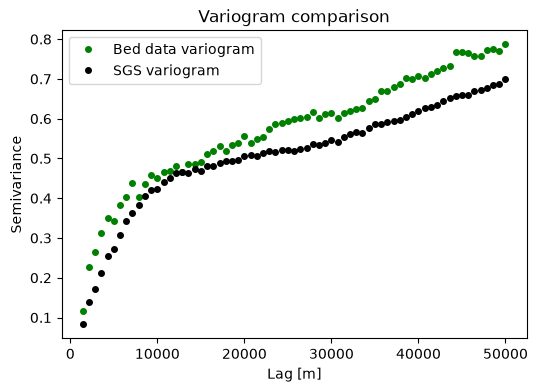

In [13]:
# experimental variogram (from beginning of script)
xe = V1.bins
ye = V1.experimental

# simple kriging variogram
xs = VS.bins
ys = VS.experimental

plt.figure(figsize=(6,4))
plt.plot(xe,ye,'og', markersize=4, label = 'Bed data variogram')
plt.plot(xs,ys,'ok', markersize=4, label = 'SGS variogram')
plt.title('Variogram comparison')
plt.xlabel('Lag [m]'); plt.ylabel('Semivariance')
plt.legend(loc='upper left')
plt.show()

We can see that the variograms are very similar. This means that SGS is reproducing the spatial statistics of observations.

Download the tutorial {Download}`here<./4_Sequential_Gaussian_Simulation.ipynb>`.